# EDA — anonymised crowdsensed WiFi corpus

Companion notebook for IEEE Latin America Transactions manuscript **ID 11172**.

- **Input:** `../data/datos_wifi_curated_anon.parquet`
- **QC:** `../data/qc_report.json`
- **Figures:** `../reports/figures/` (created on demand; relative paths only)

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
DATA = ROOT / "data" / "datos_wifi_curated_anon.parquet"
QC = ROOT / "data" / "qc_report.json"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
FIG_REL = FIG.relative_to(ROOT).as_posix()

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

df = pd.read_parquet(DATA)
qc = json.loads(QC.read_text(encoding="utf-8"))
print(
    f"Rows: {len(df):,} | BSSIDs: {df['bssid'].nunique():,} | "
    f"auditors: {df['device_id'].nunique():,}"
)
print("QC curated_rows:", qc.get("curated_rows"), "| input:", qc.get("input"))
print("Figure directory:", FIG_REL)

Rows: 53,371 | BSSIDs: 36,010 | auditors: 27
QC curated_rows: 53371 | input: data/datos_wifi_curated_anon.parquet
Figure directory: reports/figures


## Descriptive statistics

In [2]:
display(df[["level", "frequency", "estimated_distance", "distance_residual"]].describe())
print("Municipalities:", df["municipality"].nunique())
print("Security classes:\n", df["security_type_parsed"].value_counts().head(10))

,level,frequency,estimated_distance,distance_residual
count,53371.000000,53371.000000,53371.000000,5.337100e+04
mean,-82.620768,3814.094396,15.628563,1.967146e-01
std,9.758142,1521.915005,11.546910,4.081573e+00
min,-99.000000,2412.000000,0.076862,-4.985718e+01
25%,-89.000000,2437.000000,8.208914,0.000000e+00
50%,-84.000000,2462.000000,12.181879,0.000000e+00
75%,-77.000000,5300.000000,19.306977,4.440892e-16
max,-13.000000,5825.000000,63.095734,5.413548e+01


Municipalities: 45
Security classes:
 security_type_parsed
WPA2    48567
OPEN     4749
WPA        49
WEP         6
Name: count, dtype: int64


## RSSI and heuristic exposure

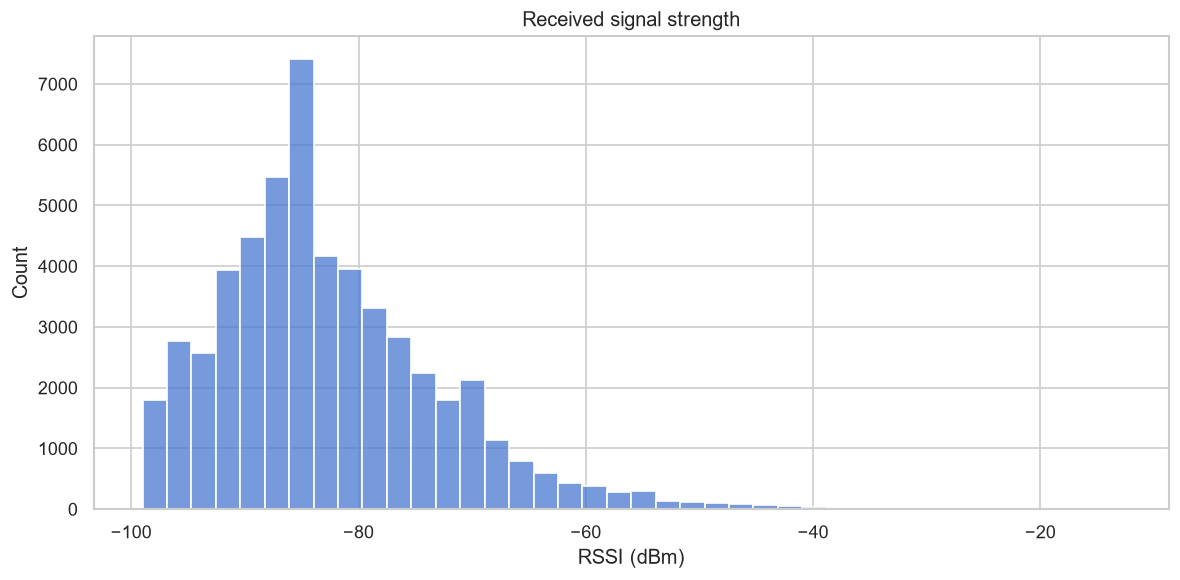

threat_type_heuristic
EVIL_TWIN_CANDIDATE     9496
OPEN_NETWORK            2096
WEP_NETWORK_DETECTED       6
Name: count, dtype: int64
Heuristic exposure rate: 0.2173090255007401


In [3]:
fig, ax = plt.subplots()
sns.histplot(df["level"], bins=40, ax=ax)
ax.set_xlabel("RSSI (dBm)")
ax.set_title("Received signal strength")
fig.tight_layout()
fig.savefig(FIG / "rssi_hist.png")
plt.show()

if "threat_type_heuristic" in df.columns:
    print(df["threat_type_heuristic"].value_counts())
if "is_anomaly_heuristic" in df.columns:
    print("Heuristic exposure rate:", float(df["is_anomaly_heuristic"].mean()))

## Spatial coverage (rounded coordinates)

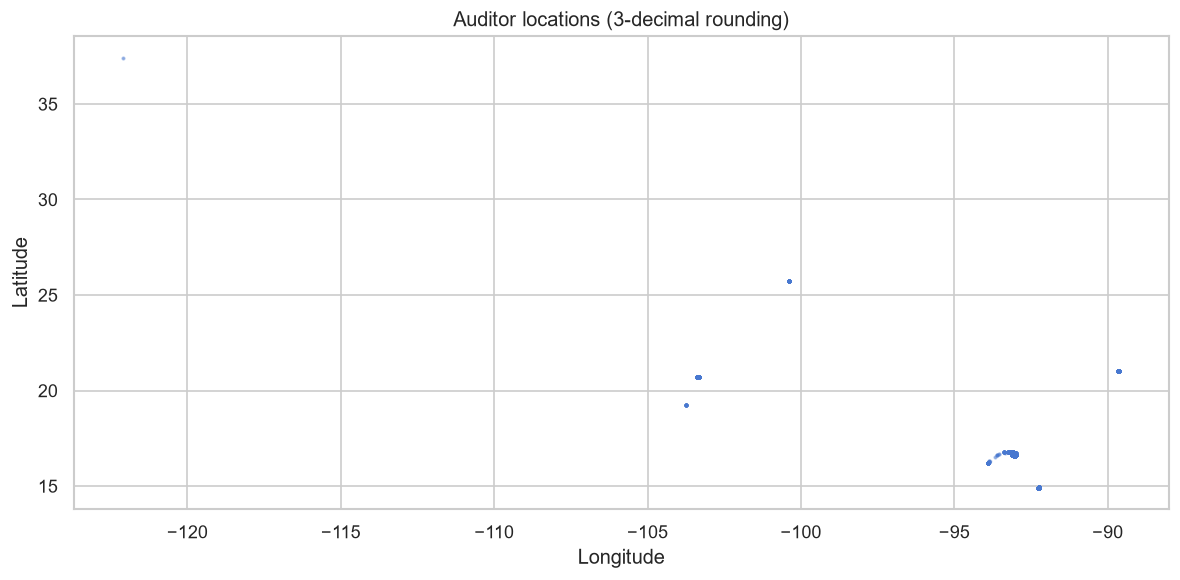

Saved figures under: reports/figures


In [4]:
fig, ax = plt.subplots()
ax.scatter(df["longitude"], df["latitude"], s=2, alpha=0.25)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Auditor locations (3-decimal rounding)")
fig.tight_layout()
fig.savefig(FIG / "spatial_scatter.png")
plt.show()
print("Saved figures under:", FIG_REL)